# 02 — Phân tích kết quả baseline

## Mục tiêu
- So sánh Logistic Regression và XGBoost.
- Phân tích Accuracy, Precision, Recall, F1 và ROC-AUC.
- Quan sát mức dao động của kết quả qua 5 fold.
- So sánh điểm train và validation để nhận diện dấu hiệu overfitting.
- Ghi nhận xét làm cơ sở cho các thực nghiệm tiếp theo.

Notebook sử dụng kết quả cross-validation trên tập train.
Tập test chưa được sử dụng để đánh giá.

In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display


sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

METRICS = ["accuracy", "precision", "recall", "f1", "roc_auc"]

METRIC_LABELS = {
    "accuracy": "Accuracy",
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1-score",
    "roc_auc": "ROC-AUC",
}

MODEL_LABELS = {
    "logistic_regression": "Logistic Regression",
    "xgboost": "XGBoost",
}

In [3]:
current_dir = Path.cwd()

if (current_dir / "outputs" / "experiments").is_dir():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "outputs" / "experiments").is_dir():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError("Không tìm thấy outputs/experiments.")

RUN_ID = "baseline_20261029_170736_811841"

RUN_DIR = PROJECT_ROOT / "outputs" / "experiments" / RUN_ID

if not RUN_DIR.is_dir():
    raise FileNotFoundError(f"Không tìm thấy lần chạy: {RUN_DIR}")

ANALYSIS_DIR = RUN_DIR / "analysis"
FIGURE_DIR = ANALYSIS_DIR / "figures"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Đang phân tích:", RUN_DIR)

Đang phân tích: d:\HK261\AI_KHDL\Assignment\outputs\experiments\baseline_20261029_170736_811841


In [4]:
comparison = pd.read_csv(RUN_DIR / "comparison.csv")
fold_results = pd.read_csv(RUN_DIR / "cv_results.csv")

with (RUN_DIR / "config.json").open(encoding="utf-8") as file:
    config = json.load(file)

print("Loại thực nghiệm:", config["experiment"])
print("Số fold:", config["n_splits"])
print("Random state:", config["random_state"])
print("Feature Engineering:", config["feature_engineering"])
print("Resampling:", config["resampling"])

display(comparison)
display(fold_results.head())

Loại thực nghiệm: baseline
Số fold: 5
Random state: 42
Feature Engineering: False
Resampling: None


,model,train_accuracy_mean,train_accuracy_std,val_accuracy_mean,val_accuracy_std,train_precision_mean,train_precision_std,val_precision_mean,val_precision_std,train_recall_mean,train_recall_std,val_recall_mean,val_recall_std,train_f1_mean,train_f1_std,val_f1_mean,val_f1_std,train_roc_auc_mean,train_roc_auc_std,val_roc_auc_mean,val_roc_auc_std,fit_time_seconds_mean
0,logistic_regression,0.806088,0.003452,0.801919,0.013287,0.661179,0.007057,0.652405,0.029403,0.552174,0.010734,0.543144,0.045955,0.601755,0.008660,0.592114,0.033428,0.849572,0.003404,0.846122,0.014032,0.041458
1,xgboost,0.881568,0.003817,0.798191,0.008757,0.821341,0.009380,0.650098,0.025488,0.707692,0.012368,0.520401,0.023483,0.760233,0.008557,0.577696,0.018257,0.950358,0.002146,0.841265,0.008417,0.129285


,model,fold,fit_time_seconds,score_time_seconds,train_accuracy,val_accuracy,train_precision,val_precision,train_recall,val_recall,train_f1,val_f1,train_roc_auc,val_roc_auc
0,logistic_regression,1,0.046292,0.031357,0.807411,0.798580,0.664329,0.645161,0.554348,0.535117,0.604376,0.585009,0.849117,0.847810
1,logistic_regression,2,0.040239,0.022721,0.810739,0.781721,0.671329,0.607287,0.561873,0.501672,0.611743,0.549451,0.854407,0.825111
2,logistic_regression,3,0.042106,0.029154,0.806967,0.802130,0.660433,0.658333,0.561037,0.528428,0.606691,0.586271,0.851170,0.841888
3,logistic_regression,4,0.035411,0.023243,0.802529,0.816327,0.656762,0.664286,0.535953,0.622074,0.590239,0.642487,0.845501,0.862797
4,logistic_regression,5,0.043240,0.022467,0.802795,0.810835,0.653041,0.686957,0.547659,0.528428,0.595725,0.597353,0.847665,0.853001


In [5]:
assert not comparison["model"].duplicated().any()
assert not fold_results.duplicated(["model", "fold"]).any()

assert set(comparison["model"]) == set(fold_results["model"])

fold_counts = fold_results.groupby("model")["fold"].nunique()

assert fold_counts.eq(config["n_splits"]).all()

score_columns = [
    f"{split}_{metric}"
    for split in ["train", "val"]
    for metric in METRICS
]

assert fold_results[score_columns].notna().all().all()

print("Kết quả hợp lệ.")
display(fold_counts.rename("number_of_folds"))

Kết quả hợp lệ.


model
logistic_regression    5
xgboost                5
Name: number_of_folds, dtype: int64

In [6]:
validation_table = pd.DataFrame({
    "Model": comparison["model"].map(MODEL_LABELS),
})

for metric in METRICS:
    validation_table[METRIC_LABELS[metric]] = [
        f"{mean:.4f} ± {std:.4f}"
        for mean, std in zip(
            comparison[f"val_{metric}_mean"],
            comparison[f"val_{metric}_std"],
        )
    ]

display(validation_table)

validation_table.to_csv(
    ANALYSIS_DIR / "validation_summary.csv",
    index=False,
)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.8019 ± 0.0133,0.6524 ± 0.0294,0.5431 ± 0.0460,0.5921 ± 0.0334,0.8461 ± 0.0140
1,XGBoost,0.7982 ± 0.0088,0.6501 ± 0.0255,0.5204 ± 0.0235,0.5777 ± 0.0183,0.8413 ± 0.0084


## So sánh kết quả validation

Các giá trị được trình bày dưới dạng trung bình ± độ lệch chuẩn
qua 5 fold.

- Logistic Regression đạt điểm validation trung bình cao hơn
  XGBoost ở cả năm chỉ số trong thực nghiệm hiện tại.
- F1 của Logistic Regression là 0,5921; XGBoost là 0,5777.
- ROC-AUC của Logistic Regression là 0,8461; XGBoost là 0,8413.
- Chênh lệch còn nhỏ, chưa đủ cơ sở kết luận một thuật toán
  luôn tốt hơn thuật toán còn lại.
- Độ lệch chuẩn mô tả dao động giữa các fold, không phải
  khoảng tin cậy.

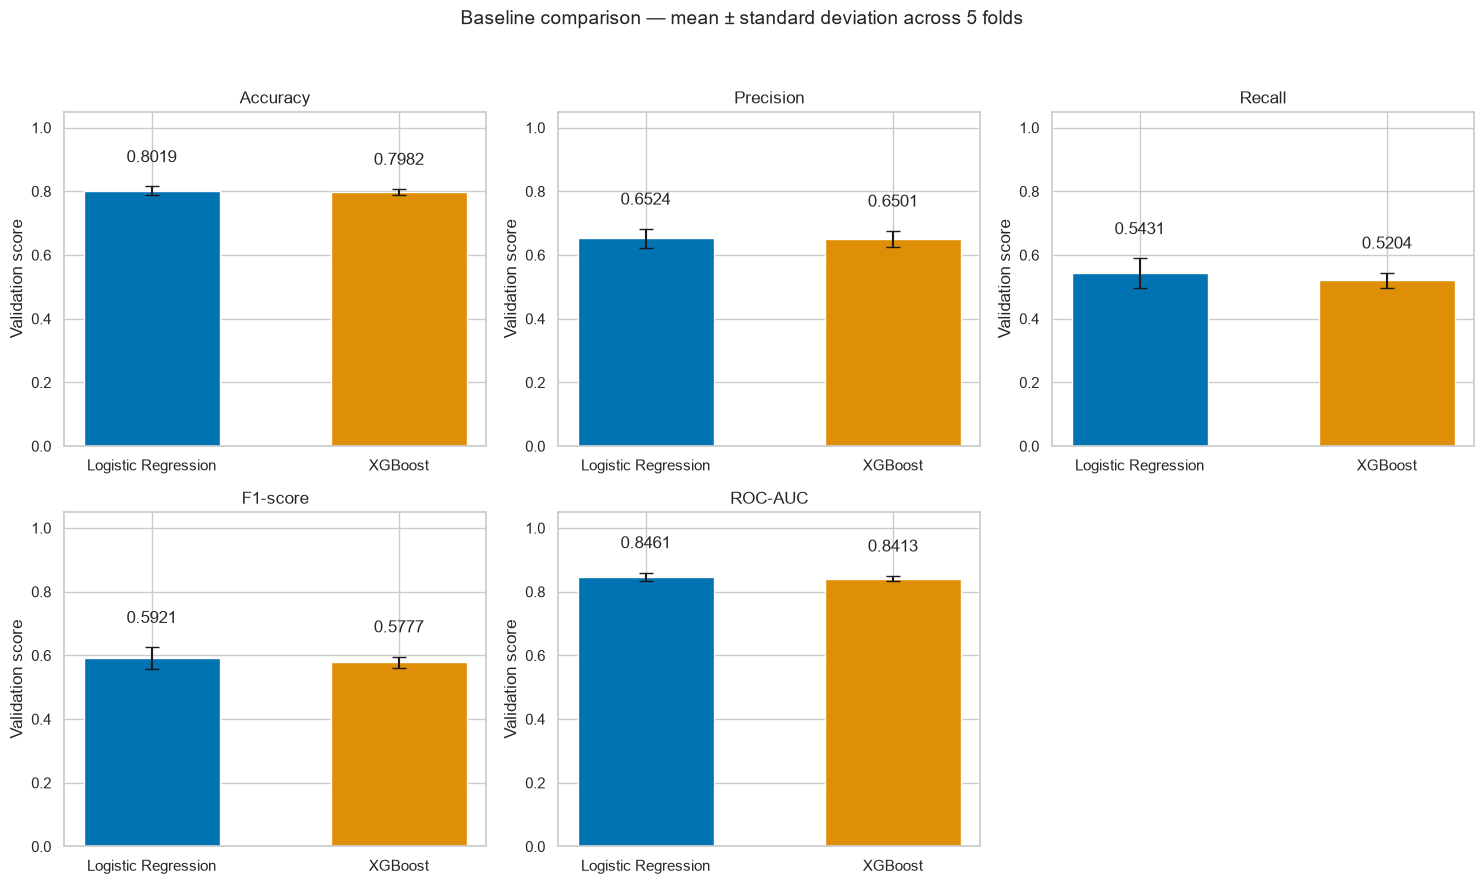

In [7]:
model_labels = comparison["model"].map(MODEL_LABELS).tolist()
colors = sns.color_palette("colorblind", n_colors=len(comparison))

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, metric in zip(axes.flat, METRICS):
    means = comparison[f"val_{metric}_mean"].to_numpy()
    stds = comparison[f"val_{metric}_std"].to_numpy()

    bars = ax.bar(
        model_labels,
        means,
        yerr=stds,
        capsize=5,
        color=colors,
        width=0.55,
    )

    ax.bar_label(
        bars,
        labels=[f"{value:.4f}" for value in means],
        padding=15,
    )

    ax.set_title(METRIC_LABELS[metric])
    ax.set_ylabel("Validation score")
    ax.set_ylim(0, 1.05)

axes.flat[-1].axis("off")

fig.suptitle(
    "Baseline comparison — mean ± standard deviation across 5 folds",
    fontsize=14,
)

fig.tight_layout(rect=[0, 0, 1, 0.95])

fig.savefig(
    FIGURE_DIR / "validation_metrics.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [8]:
gap_table = comparison[
    [
        "model",
        "train_f1_mean",
        "val_f1_mean",
        "train_roc_auc_mean",
        "val_roc_auc_mean",
    ]
].copy()

gap_table["f1_gap"] = (
    gap_table["train_f1_mean"] - gap_table["val_f1_mean"]
)

gap_table["roc_auc_gap"] = (
    gap_table["train_roc_auc_mean"] - gap_table["val_roc_auc_mean"]
)

gap_table["model"] = gap_table["model"].map(MODEL_LABELS)

display(gap_table.round(4))

gap_table.to_csv(
    ANALYSIS_DIR / "train_validation_gaps.csv",
    index=False,
)

,model,train_f1_mean,val_f1_mean,train_roc_auc_mean,val_roc_auc_mean,f1_gap,roc_auc_gap
0,Logistic Regression,0.6018,0.5921,0.8496,0.8461,0.0096,0.0035
1,XGBoost,0.7602,0.5777,0.9504,0.8413,0.1825,0.1091


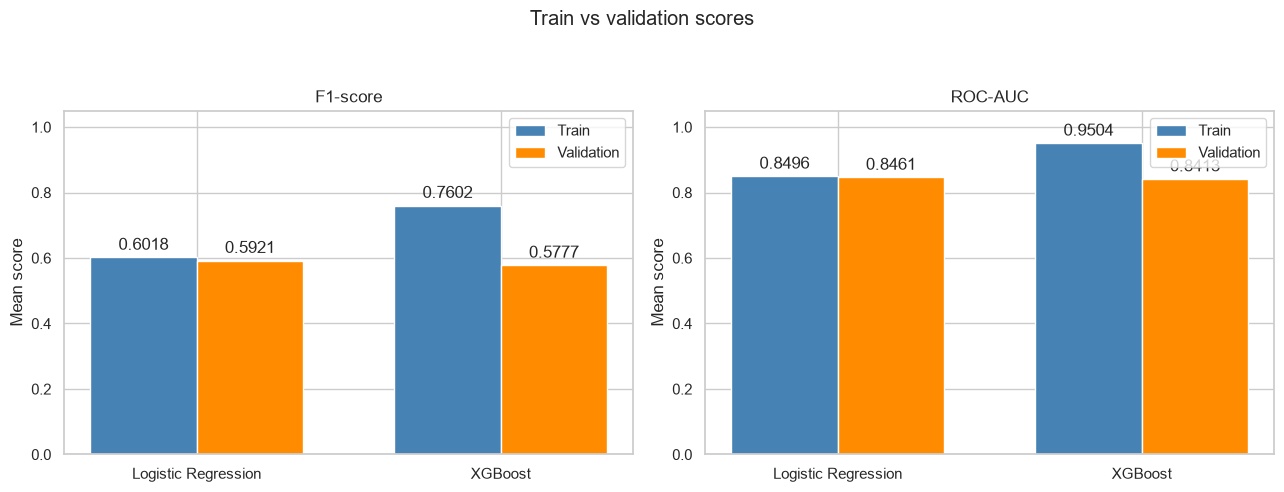

In [9]:
x = np.arange(len(comparison))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, metric in zip(axes, ["f1", "roc_auc"]):
    train_bars = ax.bar(
        x - width / 2,
        comparison[f"train_{metric}_mean"],
        width,
        label="Train",
        color="steelblue",
    )

    val_bars = ax.bar(
        x + width / 2,
        comparison[f"val_{metric}_mean"],
        width,
        label="Validation",
        color="darkorange",
    )

    ax.bar_label(train_bars, fmt="%.4f", padding=3)
    ax.bar_label(val_bars, fmt="%.4f", padding=3)

    ax.set_xticks(x)
    ax.set_xticklabels(model_labels)
    ax.set_title(METRIC_LABELS[metric])
    ax.set_ylabel("Mean score")
    ax.set_ylim(0, 1.05)
    ax.legend()

fig.suptitle("Train vs validation scores")
fig.tight_layout(rect=[0, 0, 1, 0.93])

fig.savefig(
    FIGURE_DIR / "train_vs_validation.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## Khoảng cách train và validation

Logistic Regression có điểm train và validation gần nhau:
F1 gap khoảng 0,0096 và ROC-AUC gap khoảng 0,0035.

XGBoost có khoảng cách lớn hơn:
F1 gap khoảng 0,1825 và ROC-AUC gap khoảng 0,1091.

Kết quả cho thấy XGBoost có dấu hiệu overfitting ở cấu hình baseline:
mô hình đạt điểm cao trên dữ liệu huấn luyện nhưng giảm đáng kể
trên validation.

Khoảng cách nhỏ của Logistic Regression không có nghĩa mô hình
đã tối ưu; vẫn cần xem xét mức điểm thực tế, đặc biệt là Recall.

In [10]:
f1_by_fold = fold_results.pivot(
    index="fold",
    columns="model",
    values="val_f1",
).rename(columns=MODEL_LABELS)

auc_by_fold = fold_results.pivot(
    index="fold",
    columns="model",
    values="val_roc_auc",
).rename(columns=MODEL_LABELS)

print("Validation F1 theo fold:")
display(f1_by_fold.round(4))

print("Validation ROC-AUC theo fold:")
display(auc_by_fold.round(4))

Validation F1 theo fold:


model,Logistic Regression,XGBoost
fold,,
1,0.5850,0.5746
2,0.5495,0.5492
3,0.5863,0.5949
4,0.6425,0.5923
5,0.5974,0.5775


Validation ROC-AUC theo fold:


model,Logistic Regression,XGBoost
fold,,
1,0.8478,0.8371
2,0.8251,0.8295
3,0.8419,0.8417
4,0.8628,0.8474
5,0.8530,0.8507


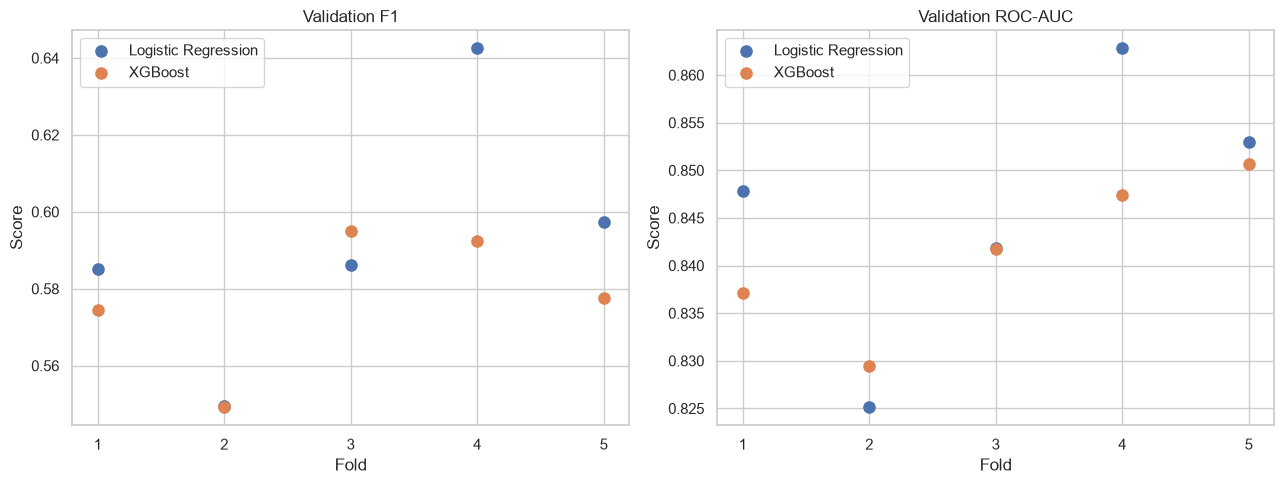

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, table, title in [
    (axes[0], f1_by_fold, "Validation F1"),
    (axes[1], auc_by_fold, "Validation ROC-AUC"),
]:
    for column in table.columns:
        ax.scatter(
            table.index,
            table[column],
            label=column,
            s=65,
        )

    ax.set_xticks(table.index)
    ax.set_xlabel("Fold")
    ax.set_ylabel("Score")
    ax.set_title(title)
    ax.legend()

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "validation_scores_by_fold.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## Kết luận baseline

### Kết quả chính

Thực nghiệm so sánh Logistic Regression và XGBoost trên cùng
5 fold Stratified Cross-Validation, sử dụng 19 đặc trưng gốc,
chưa Feature Engineering, tuning hoặc xử lý mất cân bằng.

Logistic Regression đạt:
- Accuracy: 0,8019.
- Precision: 0,6524.
- Recall: 0,5431.
- F1: 0,5921.
- ROC-AUC: 0,8461.

XGBoost đạt:
- Accuracy: 0,7982.
- Precision: 0,6501.
- Recall: 0,5204.
- F1: 0,5777.
- ROC-AUC: 0,8413.

### Nhận xét

1. Logistic Regression có điểm validation trung bình cao hơn
   XGBoost trong các cấu hình baseline đã thử.

2. XGBoost có khoảng cách train/validation lớn, cho thấy dấu hiệu
   overfitting ở cấu hình hiện tại.

3. Recall của cả hai mô hình còn hạn chế. Với ngưỡng phân loại
   mặc định, hai mô hình mới phát hiện được khoảng một nửa
   khách hàng thực sự rời bỏ.

4. XGBoost có độ dao động qua các fold thấp hơn ở F1 và ROC-AUC
   trong lần chia này, nhưng điểm trung bình vẫn thấp hơn.

5. Chênh lệch giữa hai mô hình còn nhỏ. Chưa thể kết luận
   Logistic Regression luôn tốt hơn XGBoost.

### Thực nghiệm tiếp theo

- Bổ sung Decision Tree và Random Forest để hoàn thiện bảng baseline.
- So sánh trước và sau Feature Engineering.
- Tối ưu siêu tham số, đặc biệt kiểm chứng các cấu hình
  giảm overfitting của XGBoost.
- Cân nhắc class weight hoặc điều chỉnh ngưỡng trên validation
  nếu cần cải thiện Recall.

Các kết quả hiện tại là kết quả cross-validation trên tập train.
Tập test được giữ cho đánh giá cuối cùng.